# Demo 2.2: OVReader: at which layer is the next sub-goal already in the residual stream?

**Question.** GoalScope (Demo 2) reads what the 122 goal heads **write**. Those heads sit in layers 28–55. Is the
next sub-goal already present in the residual stream *before* they write it, and from which layer on? A plain
residual-stream readout does not answer this (Demo 2, section 7: it barely works at any layer), because the residual
holds many things in many directions. We need to look at the residual **through the goal heads' eyes**.

**Method (OVReader).** Take the residual `h` after layer `L` at a pivot token. Pretend each goal head `(l, j)`
attended to it, and compute what that head would then write: its full OV map on the normalized residual,
`W_O,j · W_V,kv(j) · (g_l ⊙ h)` (`g_l` = the RMSNorm gain the head reads through). Average the unit-length writes over
the 122 heads into one direction `h_ov`, and steer the same GoalScope probe with it (additive_norm, α 0.15, layers
35–45). If the probe verbalizes the next sub-goal, the residual after layer `L` already carries it, in the direction
the goal heads would read and write it.

**What you'll see.** Demo 2's spec, read out from the residual after each of 19 layers at the four pivots, judged by
the GoalScope rubric in both modes (faithfulness: does the verbalization describe the next line? causality: does a
C++ stub steered by it implement the sub-goal?), next to the GoalScope skyline (the goal heads' actual output).

**Paper.** App. "Tracking the Sub-Goal Encoding in Residual Representation" (`Text/Appendix/ovreader.tex`,
`fig:ovreader`, `fig:ov-by-pivot`). As the paper notes, a readable residual at layer `L` does not mean the sub-goal is
*computed* at `L`: the OV map may lift a weak signal into a legible one.

Needs one 80 GB GPU (Qwen2.5-Coder-32B-Instruct in bf16). The executed outputs are saved in this file.

In [1]:
# repo root = first parent dir that contains src/
import os, sys
_d = os.getcwd()
while _d != '/' and not os.path.isdir(os.path.join(_d, 'src')):
    _d = os.path.dirname(_d)
sys.path.insert(0, _d); os.chdir(_d)
print('repo root:', _d)

# no progress bars: keeps tqdm / HF widget outputs out of the saved notebook
os.environ['TQDM_DISABLE'] = '1'
import functools, tqdm.std, tqdm.notebook, transformers, huggingface_hub
for _c in (tqdm.std.tqdm, tqdm.notebook.tqdm):   # tqdm.notebook ignores TQDM_DISABLE, so force disable=True
    _c.__init__ = functools.partialmethod(_c.__init__, disable=True)
transformers.utils.logging.disable_progress_bar()
huggingface_hub.utils.disable_progress_bars()

repo root: /disk/u/arnab/Codes/Projects/goals


## Config
The constants of `scripts/evaluation/eval_ov_reader.py` (no flags there): the 122 goal heads, OVReader α 0.15,
GoalScope skyline α 0.1, steer layers 35–45, 64-token readouts and rollout, the same 19 probe layers.

**Why this example (`list[int]_python_016`).** It is Demo 2's spec (next sub-goal: "whether any value appears more
than once"), so the GoalScope readouts there are this notebook's skyline. In the reported OVReader run its `eq` pivot is
unreadable from the residual through layer 30 and readable from layer 36 on, in both modes: the typical shape of the
pooled curve.

In [2]:
CUDA        = '6'
MODEL       = 'Qwen/Qwen2.5-Coder-32B-Instruct'
HEAD_SET    = 'head_sets/Qwen2.5-Coder-32B-Instruct/goal__lam20_thr0.9_band25-56.json'   # the 122 goal heads
SPEC_ID     = 'list[int]_python_016'
OV_ALPHA    = 0.15                     # OVReader steering strength (additive_norm)
SKY_ALPHA   = 0.1                      # GoalScope skyline (the goal heads' output, Demo 2)
STEER_LAYERS = (35, 46)                # half-open: the probe is steered at layers 35..45
SEED        = 123

os.environ['CUDA_VISIBLE_DEVICES'] = CUDA

## Load the model, the goal heads and the OVReader
`OVReader(mt, heads)` precomputes, for every goal head, the three small factors of its OV map (`W_O` slice, the GQA
`W_V` slice, the input RMSNorm gain); `resid_ov_vec(h)` applies them to any residual.

In [3]:
import json, collections
import numpy as np
import torch
import matplotlib.pyplot as plt
from rich import print as rprint
from rich.console import Console
from rich.table import Table
from rich.markup import escape

from src.models import ModelandTokenizer
from src.utils import env_utils, experiment_utils
from src.goals.head_sets import load_json_heads
from src.goals.goalscope import OVReader, apply_goalscope, _build_causality_prompt, CAUSAL_PREFIX
from scripts.evaluation.eval_goalscope import (
    DEFAULT_DATASET, ALL_DATATYPES, MAX_NEW_TOKENS, GEN_MAX_NEW_TOKENS,
    load_locked_datapoints, build_prompt, generate_completion, frontier_impl_span, pivot_positions, hard_eval,
)
from scripts.evaluation import ov_reader_io as ovio

console = Console(width=150, highlight=False)
torch.set_grad_enabled(False)
experiment_utils.set_seed(SEED)

mt = ModelandTokenizer(model_key=MODEL, dtype=torch.bfloat16, device_map={'': 0}, attn_implementation='eager')
heads = load_json_heads(HEAD_SET, mt.n_layer, mt.n_heads)
ov = OVReader(mt, heads)
PROBE_LAYERS = sorted(set(list(range(0, 37, 6)) + list(range(38, 56, 2)) + list(range(56, mt.n_layer, 4)) + [mt.n_layer - 1]))
print(f'goal heads: {len(heads)} (layers {min(l for l, _ in heads)}-{max(l for l, _ in heads)}) | probe layers: {PROBE_LAYERS}')

Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


goal heads: 122 (layers 28-55) | probe layers: [0, 6, 12, 18, 24, 30, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 60, 63]


## 1. The spec, the rollout and the pivots
As in Demo 2: the locked-corpus prompt prefilled up to `{var} =` of the next sub-goal, the greedy rollout, the
implementation span the readouts are graded against, and the pivot positions (the eval also reads `first_impl`, the
first generated token; it is not reported).

In [4]:
datapoints, _ = load_locked_datapoints(DEFAULT_DATASET, ALL_DATATYPES)
inst = dict(datapoints)[SPEC_ID]
prompt, var = build_prompt(mt, inst)
completion = generate_completion(mt, prompt, GEN_MAX_NEW_TOKENS)
full_text = prompt + completion
impl_span = frontier_impl_span(prompt, completion, var)
pivs = pivot_positions(mt, prompt, full_text, ovio.PIVOT_ORDER)
REPORTED_PIVOTS = ['prev_end', 'indent', 'var', 'eq']

rprint('[dim]' + escape(prompt.split('<code>')[-1]) + '[/dim]' + '[bold green]' + escape(completion.split(chr(10))[0]) + '[/bold green]')
print(f'\nnext sub-goal: "{inst.expected_next_desc}"   implementation span (gold): {impl_span}')
ids = mt.tokenizer(full_text, add_special_tokens=False)['input_ids']
print('pivots:', {p: (q, mt.tokenizer.decode([ids[q]])) for p, q in pivs.items()})

def func(nums: list[int]):
    a = sum(1 for x in nums if x % 2 != 0)
    b = sum(1 for x in nums if x > 0)
    c = all(nums[i] <= nums[i+1] for i in range(len(nums)-1))
    d = len(nums) != len(set(nums))


next sub-goal: "whether any value appears more than once"   implementation span (gold): d = len(nums) != len(set(nums))
pivots: {'prev_end': (180, '))\n'), 'indent': (181, '   '), 'var': (182, ' d'), 'eq': (183, ' ='), 'first_impl': (184, ' len')}


## 2. Readouts: the GoalScope skyline, and OVReader after every probe layer
Exactly the eval's calls, per mode: one `apply_goalscope` over all pivots (the skyline), then per pivot one
`ov.apply_probe_on_prompt` that extracts the residual after each of the 19 layers in a single forward and verbalizes
all of them. In causality mode the probe is the C++ stub `bool check (auto value){`, and the readout is graded with
the stub prepended (`CAUSAL_PREFIX`).

In [5]:
MODES = ['faithfulness', 'causality']
apos = sorted(set(pivs.values()))
reads = {}                                                   # (mode, pivot, layer | 'goalscope') -> readout
for mode in MODES:
    sky = {r['pos']: r['patched_gen'] for r in apply_goalscope(
        full_text, mt=mt, selected_heads=heads, strategy='additive_norm', steer_layer_range=STEER_LAYERS,
        alpha=SKY_ALPHA, n_steer_tokens='all', max_new_tokens=MAX_NEW_TOKENS, include_noncode=False,
        token_positions=apos, goalscope_prompt=_build_causality_prompt(mt) if mode == 'causality' else None)}
    for p, q in pivs.items():
        reads[mode, p, 'goalscope'] = sky.get(q, '')
        by_layer = ov.apply_probe_on_prompt(full_text, q, PROBE_LAYERS, mode=mode, steer_layers=list(range(*STEER_LAYERS)),
                                            max_new_tokens=MAX_NEW_TOKENS, alpha=OV_ALPHA)
        for L in PROBE_LAYERS:
            reads[mode, p, L] = by_layer.get(L, '')
print(len(reads), 'readouts')

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


200 readouts


## 3. Judge
`hard_eval` is the GoalScope rubric (Claude, cached on disk): **YES** = the readout names a nontrivial part of the
next line's implementation. Below, the `eq` pivot layer by layer: the faithfulness verbalization and the causality
C++ body with their verdicts.

In [6]:
prefix = {'faithfulness': '', 'causality': CAUSAL_PREFIX}
verd = {k: hard_eval(prefix[k[0]] + (ro or ''), impl_span, k[0])['verdict'] for k, ro in reads.items()}

V = lambda v: '[bold green]YES[/]' if v == 'YES' else f'[red]{v}[/]'
one = lambda s, n=70: escape(' '.join(s.split())[:n] + ('...' if len(' '.join(s.split())) > n else ''))
t = Table(title=f'{SPEC_ID} @ eq: "{inst.expected_next_desc}"', show_lines=False)
t.add_column('source'); t.add_column('faithfulness readout'); t.add_column(''); t.add_column('causality readout (C++ body)'); t.add_column('')
for L in PROBE_LAYERS + ['goalscope']:
    name = 'GoalScope (goal-head output)' if L == 'goalscope' else f'residual after layer {L}'
    t.add_row(name, one(reads['faithfulness', 'eq', L]), V(verd['faithfulness', 'eq', L]),
              one(reads['causality', 'eq', L], 50), V(verd['causality', 'eq', L]))
console.print(t)

                                           list_python_016 @ eq: "whether any value appears more than once"                                           
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┓
┃ source                       ┃ faithfulness readout                             ┃         ┃ causality readout (C++ body)                     ┃     ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━┩
│ residual after layer 0       │ I'm not doing anything; I'm just defining a      │ NO_INFO │ return value > 0; }                              │ NO  │
│                              │ variable to hold a value t...                    │         │                                                  │     │
│ residual after layer 6       │ I'm not doing anything; I'm just checking if a   │ NO      │ return value > 0; }                              │ NO  │
│                              │ value is less than or e...                       │         │                                                  │     │
│ residual after layer 12      │ I'm checking for conditions related to the logic │ NO_INFO │ return (value & 0b1010) == 0b101; }              │ NO  │
│                              │ of the code, likely i...                         │         │                                                  │     │
│ residual after layer 18      │ I'm calculating the difference between two       │ NO      │ return value; } // Placeholder for the division  │ NO  │
│                              │ values to find the greatest...                   │         │ to...                                            │     │
│ residual after layer 24      │ I'm checking for data integrity and ensuring the │ NO_INFO │ return value > 0; }                              │ NO  │
│                              │ code is executing pro...                         │         │                                                  │     │
│ residual after layer 30      │ I'm checking if the variable `data` is defined   │ NO      │ return std::is_same<decltype(value),             │ NO  │
│                              │ and if it's a dictionar...                       │         │ bool>::value;...                                 │     │
│ residual after layer 36      │ I'm checking if there are any duplicate elements │ YES     │ std::set<int> testSet; for(int i = 0; i <        │ YES │
│                              │ in the list, specific...                         │         │ value.si...                                      │     │
│ residual after layer 38      │ I'm checking if there are any duplicate elements │ YES     │ return std::any_of(begin(value), end(value),     │ NO  │
│                              │ in the list by conver...                         │         │ [](au...                                         │     │
│ residual after layer 40      │ I'm checking if there are any duplicate elements │ YES     │ return value != std::set(value.begin(),          │ YES │
│                              │ in the list by compar...                         │         │ value.end(...                                    │     │
│ residual after layer 42      │ I'm identifying if there's any variable or data  │ YES     │ return value.size() > std::set(value.begin(),    │ YES │
│                              │ structure that has mor...                        │         │ valu...                                          │     │
│ residual after layer 44      │ I'm checking if there's any element in the list  │ YES     │ return value.size() > std::set(value.begin(),    │ YES │
│                              │ that has more than one...                        │         │ valu...                                          │     │
│ residual after layer 46      │ I'm identifying if there's any variable i

The whole grid: every probe layer × the four reported pivots, in both modes (green = YES), next to how many of the 122
goal heads sit in each layer.

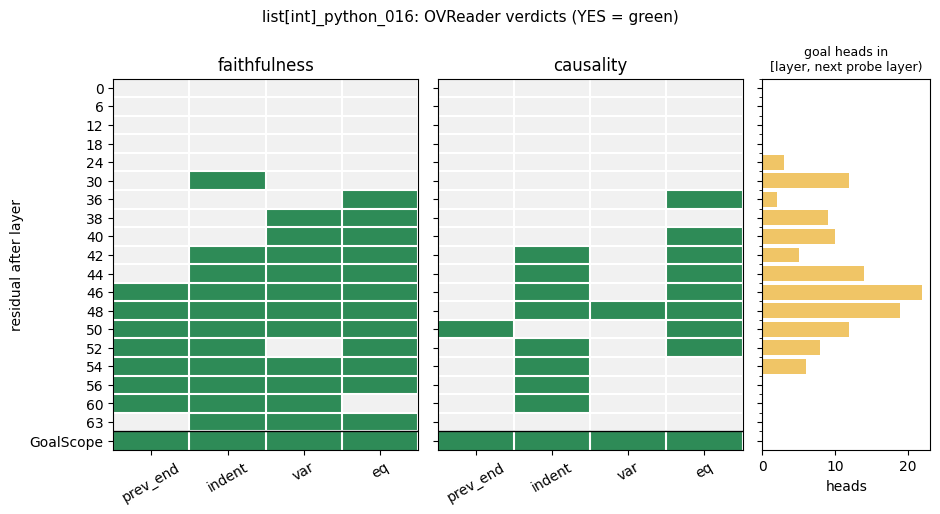

In [7]:
head_counts = collections.Counter(l for l, _ in heads)
fig, axes = plt.subplots(1, 3, figsize=(9.5, 5.2), gridspec_kw=dict(width_ratios=[4, 4, 2.2]), sharey=True)
y = np.arange(len(PROBE_LAYERS) + 1)
ylabels = [str(L) for L in PROBE_LAYERS] + ['GoalScope']
for ax, mode in zip(axes[:2], MODES):
    M = np.array([[verd[mode, p, L] == 'YES' for p in REPORTED_PIVOTS] for L in PROBE_LAYERS + ['goalscope']], float)
    ax.imshow(M, cmap=plt.matplotlib.colors.ListedColormap(['#f1f1f1', '#2e8b57']), vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(4)); ax.set_xticklabels(REPORTED_PIVOTS, rotation=30)
    ax.set_title(mode); ax.axhline(len(PROBE_LAYERS) - 0.5, color='black', lw=1)
    ax.set_xticks(np.arange(-0.5, 4), minor=True); ax.set_yticks(y - 0.5, minor=True)
    ax.grid(which='minor', color='white', lw=1.5); ax.tick_params(which='minor', length=0)
axes[0].set_yticks(y); axes[0].set_yticklabels(ylabels); axes[0].set_ylabel('residual after layer')
counts = [sum(head_counts[l] for l in range(L, L2)) for L, L2 in zip(PROBE_LAYERS, PROBE_LAYERS[1:] + [mt.n_layer])] + [0]
axes[2].barh(y, counts, color='#E69F00', alpha=0.6)
axes[2].set_title('goal heads in\n[layer, next probe layer)', fontsize=9); axes[2].set_xlabel('heads')
fig.suptitle(f'{SPEC_ID}: OVReader verdicts (YES = green)', fontsize=11)
fig.tight_layout(); plt.show()

How to read it. Through layer 30 the residual, seen through the goal heads' OV maps, says nothing about the next
sub-goal at any pivot. At `eq` it reads out as the duplicate check from layer 36 on in faithfulness (all but layer
60), and in causality from layer 36 to about 52, where a C++ stub steered by it implements the check; past layer 54
the causality readouts lose it again. The earlier pivots light up later and more sparsely (`prev_end` only from
layer 46 in faithfulness, and almost never in causality). So the information is available in the residual over the
band where the goal heads sit (layers 28-55), most clearly at the pivot right before the line is written. The skyline,
the heads' own output, is YES at every pivot in both modes.

## 4. Cross-check against the reported run, then the pooled curves
The reported records of this spec (`results/evaluation/ov-reader/<model>/<layer | goalscope>/<mode>/<leaf>/records.jsonl`):
same readouts and verdicts (up to bf16 nondeterminism on other hardware). Then the paper's `fig:ovreader`: the YES
rate per layer, mean over the 4 pivots × 4 datatypes (all 253 specs), with the goal heads per layer behind it (as in
`notebooks/fig_n_table_generators/ovreader.ipynb` cell 4).

 this notebook vs. the reported run (4 pivots x 20 sources per mode) 
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ mode         ┃ same readout ┃ same verdict ┃ YES: reported / ours ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ faithfulness │ 80 / 80      │ 80 / 80      │ 45 / 45              │
│ causality    │ 80 / 80      │ 80 / 80      │ 22 / 22              │
└──────────────┴──────────────┴──────────────┴──────────────────────┘

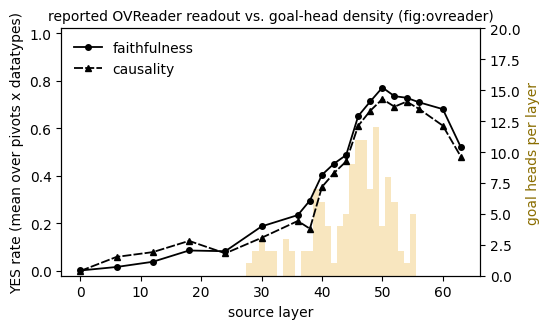

In [8]:
RR = env_utils.DEFAULT_RESULTS_DIR
DATATYPE = SPEC_ID.split('_python')[0]
LEAF = (f'heads=goal__lam20_thr0.9_band25-56__nheads=122__alpha={OV_ALPHA:g}__skyalpha={SKY_ALPHA:g}__dtype={DATATYPE}'
        f'__lang=python__nc=2-3-4__maxnew={MAX_NEW_TOKENS}__gen={GEN_MAX_NEW_TOKENS}__span=frontier__seed={SEED}')
def reported(mode, L):
    fp = ovio.ov_root(RR) / MODEL.split('/')[-1] / str(L) / mode / LEAF / 'records.jsonl'
    return {r['pivot']: r for r in map(json.loads, open(fp)) if r['spec'] == SPEC_ID}

t = Table(title='this notebook vs. the reported run (4 pivots x 20 sources per mode)')
t.add_column('mode'); t.add_column('same readout'); t.add_column('same verdict'); t.add_column('YES: reported / ours')
for mode in MODES:
    same_ro = same_v = n = y_rep = y_ours = 0
    for L in PROBE_LAYERS + ['goalscope']:
        rep = reported(mode, L)
        for p in REPORTED_PIVOTS:
            n += 1
            same_ro += rep[p]['readout'] == prefix[mode] + reads[mode, p, L]
            same_v += rep[p]['hard'] == verd[mode, p, L]
            y_rep += rep[p]['hard'] == 'YES'; y_ours += verd[mode, p, L] == 'YES'
    t.add_row(mode, f'{same_ro} / {n}', f'{same_v} / {n}', f'{y_rep} / {y_ours}')
console.print(t)

# pooled curves (= fig:ovreader)
def pooled(mode):
    df = ovio.grid_df(RR, mode=mode, model=MODEL)
    df = df[df['pivot'].isin(REPORTED_PIVOTS) & (df['layer_idx'] != ovio.SKYLINE_IDX)].copy()
    df['layer_idx'] = df['layer_idx'].astype(int)
    m = df.groupby(['layer_idx', 'pivot'])['hard_yes'].mean().groupby('layer_idx').mean()   # mean over datatypes, then pivots
    return m.index.to_numpy(), m.to_numpy()
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax2 = ax.twinx()
ax2.bar(sorted(head_counts), [head_counts[l] for l in sorted(head_counts)], width=1.0, color='#E69F00', alpha=0.25, lw=0)
ax2.set_ylim(0, 20); ax2.set_ylabel('goal heads per layer', color='#8a6d00'); ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
for mode, ls, mk in (('faithfulness', '-', 'o'), ('causality', (0, (5, 1.2)), '^')):
    x, m = pooled(mode)
    ax.plot(x, m, color='black', ls=ls, marker=mk, ms=4, lw=1.3, label=mode)
ax.set_ylim(-0.02, 1.02); ax.set_xlabel('source layer'); ax.set_ylabel('YES rate (mean over pivots x datatypes)')
ax.set_title('reported OVReader readout vs. goal-head density (fig:ovreader)', fontsize=10); ax.legend(frameon=False, loc='upper left')
fig.tight_layout(); plt.show()

## Where this goes in the paper / how to reproduce at scale
- **Commands**: `job_list/diff_eval/ov_reader_locked.json` (8 jobs = 2 modes × 4 datatypes), e.g.
  `python -m scripts.evaluation.eval_ov_reader --mode faithfulness --datatypes list[int]`. Each job sweeps the 19
  probe layers plus the GoalScope skyline. Smoke: `--datatypes int --limit 2`, **with a scratch `RESULTS_DIR`**: the
  OVReader leaf has no `nspec` field, so a smoke run resumes into the reported directory.
- **Paper numbers** (unweighted mean over the 4 datatype leaves, `eq` pivot, faithfulness / causality): skyline .972 /
  .955, layer 48 .948 / .875, layer 56 .853 / .836, layer 63 .671 / .660, layer 24 .079 / .062, layer 0 .000 / .000.
- **Generator**: `notebooks/fig_n_table_generators/ovreader.ipynb` (cell 4 `ov_reader_combined` = `fig:ovreader`,
  cell 5 `ov_by_pivot_combined` = `fig:ov-by-pivot`).
- **Related**: Demo 2 (GoalScope on the goal heads' output, and the plain residual baseline).